# Classification Track (Part A) — Verdict Outcome Tendency Prediction
Loads preprocessed data from `preprocessing.ipynb` and runs the 5 Part-A classification algorithms and their evaluation.

**Requires `preprocessing.ipynb` to have been run first** (produces `data/processed/model_ready_data.pkl`).

In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.decomposition import PCA
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, LogisticRegression
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier, plot_tree
from sklearn.ensemble import (RandomForestRegressor, GradientBoostingRegressor, RandomForestClassifier,
                               AdaBoostClassifier, GradientBoostingClassifier, BaggingClassifier)
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVR, SVC
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.metrics import (r2_score, mean_squared_error, mean_absolute_error, accuracy_score, precision_score,
                              recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score,
                              classification_report)
import time
import warnings
warnings.filterwarnings("ignore", category=UserWarning)  # harmless DataFrame/array feature-name mismatch

pd.set_option("display.max_columns", 60)
sns.set_theme(style="whitegrid", palette="colorblind")
RANDOM_STATE = 42

### Load preprocessed train/test data

In [31]:
import joblib

artifacts = joblib.load("../data/processed/model_ready_data.pkl")
X_train_final = artifacts["X_train_final"]
X_test_final = artifacts["X_test_final"]
y_clf_train = artifacts["y_clf_train"]
y_clf_test = artifacts["y_clf_test"]
RANDOM_STATE = artifacts["RANDOM_STATE"]

print("Loaded preprocessed data. X_train_final shape:", X_train_final.shape)

Loaded preprocessed data. X_train_final shape: (194879, 37)


---
### Shared setup — class order, result trackers, evaluation function

In [32]:
CLASS_LABELS = sorted(y_clf_train.unique().tolist())
print("Class order:", CLASS_LABELS)

results_clf = []
fitted_models_clf = {}
test_preds_clf = {}
test_probas_clf = {}

def evaluate_classifier(name, y_true, y_pred, y_proba, fit_seconds, classes):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average="weighted", zero_division=0)
    rec = recall_score(y_true, y_pred, average="weighted", zero_division=0)
    f1 = f1_score(y_true, y_pred, average="weighted", zero_division=0)
    roc_auc = roc_auc_score(y_true, y_proba, multi_class="ovr", average="weighted", labels=classes)

    print(f"\n===== {name} =====")
    print(f"Accuracy={acc:.4f}  Precision(weighted)={prec:.4f}  Recall(weighted)={rec:.4f}  "
          f"F1(weighted)={f1:.4f}  ROC-AUC(OvR, weighted)={roc_auc:.4f}  (fit time {fit_seconds:.1f}s)")
    print(classification_report(y_true, y_pred, labels=classes, zero_division=0))

    cm = confusion_matrix(y_true, y_pred, labels=classes)
    fig, ax = plt.subplots(figsize=(6, 5))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=classes)
    disp.plot(ax=ax, cmap="Blues", colorbar=False, xticks_rotation=45)
    ax.set_title(f"Confusion Matrix — {name}")
    plt.tight_layout()
    plt.show()

    results_clf.append({"Model": name, "Accuracy": acc, "Precision": prec, "Recall": rec,
                         "F1": f1, "ROC_AUC_OvR": roc_auc, "Fit_Seconds": fit_seconds})
    return acc, prec, rec, f1, roc_auc

Class order: ['Dismissed', 'Judgment', 'Settled', 'Statistical', 'Transferred']


#### 1. Logistic Regression


===== Logistic Regression =====
Accuracy=0.4425  Precision(weighted)=0.5654  Recall(weighted)=0.4425  F1(weighted)=0.4637  ROC-AUC(OvR, weighted)=0.7576  (fit time 3.6s)
              precision    recall  f1-score   support

   Dismissed       0.75      0.36      0.49     22863
    Judgment       0.42      0.41      0.41      9620
     Settled       0.47      0.63      0.54     10772
 Statistical       0.10      0.47      0.16      1485
 Transferred       0.28      0.46      0.34      3980

    accuracy                           0.44     48720
   macro avg       0.40      0.47      0.39     48720
weighted avg       0.57      0.44      0.46     48720



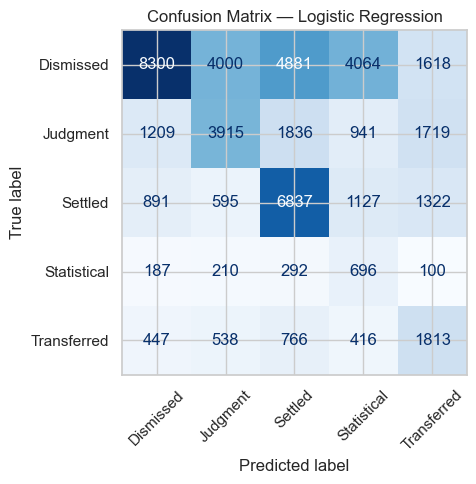

(0.4425492610837438,
 0.5654141831270527,
 0.4425492610837438,
 0.4637459505516463,
 0.7575999172040594)

In [33]:
t0 = time.time()
log_reg = LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1)
log_reg.fit(X_train_final, y_clf_train)
fit_seconds = time.time() - t0

pred_log = log_reg.predict(X_test_final)
proba_log = log_reg.predict_proba(X_test_final)

fitted_models_clf["Logistic Regression"] = log_reg
test_preds_clf["Logistic Regression"] = pred_log
test_probas_clf["Logistic Regression"] = proba_log

evaluate_classifier("Logistic Regression", y_clf_test, pred_log, proba_log, fit_seconds,
                     classes=log_reg.classes_.tolist())

Coefficient / odds interpretation — Logistic Regression

In [34]:
coef_df = pd.DataFrame(log_reg.coef_, index=log_reg.classes_, columns=X_train_final.columns)
odds_ratios = np.exp(coef_df)

print("Top 5 features (by |coefficient|) driving each class, with their odds ratio:")
for cls in log_reg.classes_:
    top_feats = coef_df.loc[cls].sort_values(key=abs, ascending=False).head(5)
    print(f"\n{cls}:")
    for feat, coef_val in top_feats.items():
        print(f"    {feat:30s}  coef={coef_val:+.3f}   odds_ratio={odds_ratios.loc[cls, feat]:.3f}")

Top 5 features (by |coefficient|) driving each class, with their odds ratio:

Dismissed:
    PC30                            coef=+1.100   odds_ratio=3.003
    PC34                            coef=-0.907   odds_ratio=0.404
    PC33                            coef=-0.840   odds_ratio=0.432
    PC35                            coef=-0.776   odds_ratio=0.460
    PC29                            coef=-0.659   odds_ratio=0.518

Judgment:
    PC36                            coef=+1.149   odds_ratio=3.154
    PC30                            coef=-0.908   odds_ratio=0.403
    PC27                            coef=-0.807   odds_ratio=0.446
    PC37                            coef=+0.797   odds_ratio=2.219
    PC33                            coef=-0.747   odds_ratio=0.474

Settled:
    PC28                            coef=+0.952   odds_ratio=2.592
    PC11                            coef=-0.687   odds_ratio=0.503
    PC8                             coef=-0.674   odds_ratio=0.509
    PC4            

#### 2. KNN Classifier

Stratified subsample class balance:
CASE_OUTCOME
Dismissed      0.469
Settled        0.221
Judgment       0.197
Transferred    0.082
Statistical    0.030
Name: proportion, dtype: float64

===== KNN Classifier =====
Accuracy=0.5709  Precision(weighted)=0.5597  Recall(weighted)=0.5709  F1(weighted)=0.5578  ROC-AUC(OvR, weighted)=0.7631  (fit time 0.0s)
              precision    recall  f1-score   support

   Dismissed       0.63      0.73      0.68     22863
    Judgment       0.52      0.41      0.46      9620
     Settled       0.50      0.55      0.53     10772
 Statistical       0.50      0.18      0.27      1485
 Transferred       0.43      0.24      0.31      3980

    accuracy                           0.57     48720
   macro avg       0.52      0.42      0.45     48720
weighted avg       0.56      0.57      0.56     48720



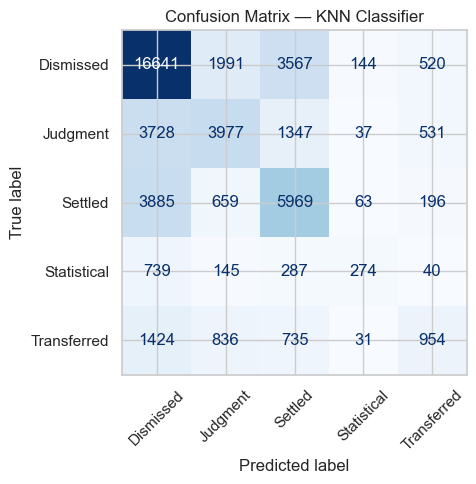

(0.5709154351395731,
 0.5596743799606415,
 0.5709154351395731,
 0.5577560945265388,
 0.763065442613126)

In [35]:
KNN_SVC_SAMPLE_SIZE = 15000
X_train_small, _, y_clf_train_small, _ = train_test_split(
    X_train_final, y_clf_train,
    train_size=KNN_SVC_SAMPLE_SIZE, stratify=y_clf_train, random_state=RANDOM_STATE
)
print("Stratified subsample class balance:")
print(y_clf_train_small.value_counts(normalize=True).round(3))

t0 = time.time()
knn_clf = KNeighborsClassifier(n_neighbors=10, weights="distance", n_jobs=-1)
knn_clf.fit(X_train_small, y_clf_train_small)
fit_seconds = time.time() - t0

pred_knn_clf = knn_clf.predict(X_test_final)
proba_knn_clf = knn_clf.predict_proba(X_test_final)

fitted_models_clf["KNN Classifier"] = knn_clf
test_preds_clf["KNN Classifier"] = pred_knn_clf
test_probas_clf["KNN Classifier"] = proba_knn_clf

evaluate_classifier("KNN Classifier", y_clf_test, pred_knn_clf, proba_knn_clf, fit_seconds,
                     classes=knn_clf.classes_.tolist())

#### 3. Naive Bayes (Gaussian)


===== Naive Bayes (Gaussian) =====
Accuracy=0.5017  Precision(weighted)=0.5067  Recall(weighted)=0.5017  F1(weighted)=0.4997  ROC-AUC(OvR, weighted)=0.7189  (fit time 0.2s)
              precision    recall  f1-score   support

   Dismissed       0.62      0.60      0.61     22863
    Judgment       0.41      0.39      0.40      9620
     Settled       0.46      0.55      0.50     10772
 Statistical       0.14      0.26      0.18      1485
 Transferred       0.34      0.15      0.21      3980

    accuracy                           0.50     48720
   macro avg       0.39      0.39      0.38     48720
weighted avg       0.51      0.50      0.50     48720



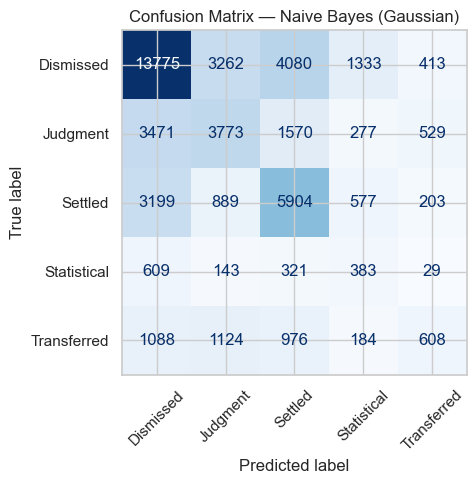

(0.5017036124794746,
 0.5066908747810341,
 0.5017036124794746,
 0.499741511399264,
 0.7189336843910188)

In [36]:
t0 = time.time()
nb_clf = GaussianNB()
nb_clf.fit(X_train_final, y_clf_train)
fit_seconds = time.time() - t0

pred_nb = nb_clf.predict(X_test_final)
proba_nb = nb_clf.predict_proba(X_test_final)

fitted_models_clf["Naive Bayes (Gaussian)"] = nb_clf
test_preds_clf["Naive Bayes (Gaussian)"] = pred_nb
test_probas_clf["Naive Bayes (Gaussian)"] = proba_nb

evaluate_classifier("Naive Bayes (Gaussian)", y_clf_test, pred_nb, proba_nb, fit_seconds,
                     classes=nb_clf.classes_.tolist())

#### 4. Decision Tree Classifier


===== Decision Tree Classifier =====
Accuracy=0.5445  Precision(weighted)=0.6201  Recall(weighted)=0.5445  F1(weighted)=0.5624  ROC-AUC(OvR, weighted)=0.8021  (fit time 9.4s)
              precision    recall  f1-score   support

   Dismissed       0.76      0.51      0.61     22863
    Judgment       0.62      0.53      0.57      9620
     Settled       0.50      0.67      0.57     10772
 Statistical       0.16      0.47      0.24      1485
 Transferred       0.30      0.50      0.37      3980

    accuracy                           0.54     48720
   macro avg       0.47      0.53      0.47     48720
weighted avg       0.62      0.54      0.56     48720



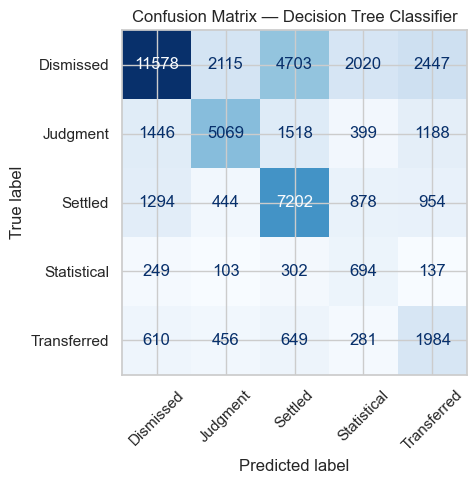

(0.5444786535303777,
 0.6201335694983382,
 0.5444786535303777,
 0.5623970057354155,
 0.8021333730394415)

In [37]:
t0 = time.time()
dt_clf = DecisionTreeClassifier(max_depth=10, class_weight="balanced", random_state=RANDOM_STATE)
dt_clf.fit(X_train_final, y_clf_train)
fit_seconds = time.time() - t0

pred_dt_clf = dt_clf.predict(X_test_final)
proba_dt_clf = dt_clf.predict_proba(X_test_final)

fitted_models_clf["Decision Tree Classifier"] = dt_clf
test_preds_clf["Decision Tree Classifier"] = pred_dt_clf
test_probas_clf["Decision Tree Classifier"] = proba_dt_clf

evaluate_classifier("Decision Tree Classifier", y_clf_test, pred_dt_clf, proba_dt_clf, fit_seconds,
                     classes=dt_clf.classes_.tolist())

Tree visualisation (top 3 levels) — Decision Tree Classifier

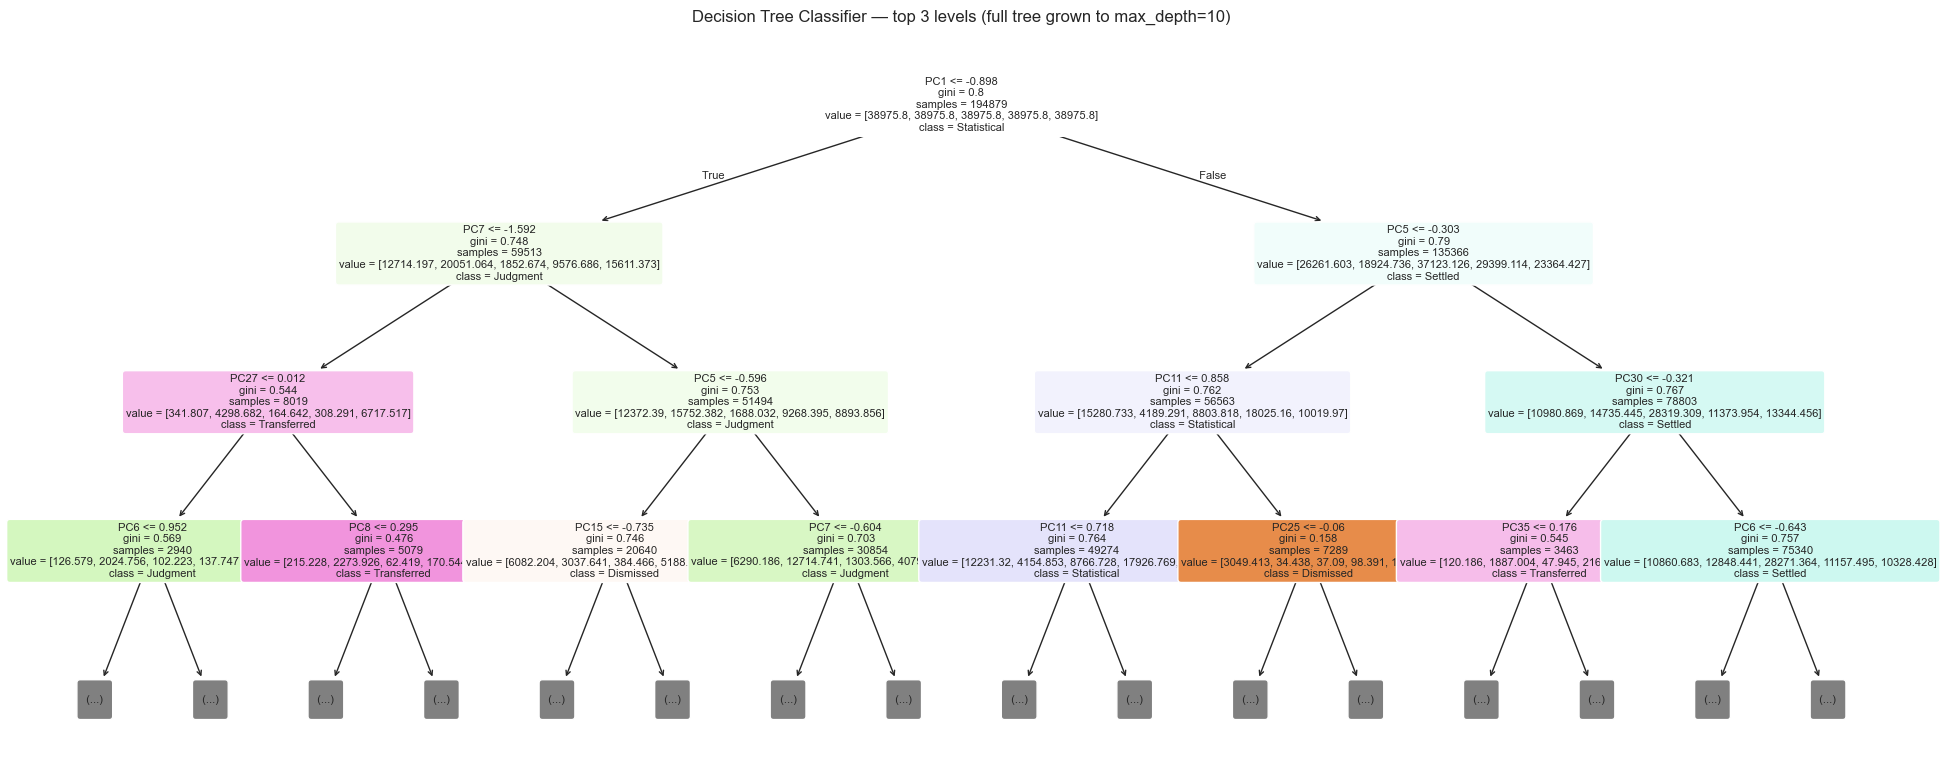

In [38]:
fig, ax = plt.subplots(figsize=(20, 8))
plot_tree(dt_clf, max_depth=3, feature_names=X_train_final.columns, class_names=dt_clf.classes_,
          filled=True, rounded=True, fontsize=8, ax=ax)
ax.set_title("Decision Tree Classifier — top 3 levels (full tree grown to max_depth=10)")
plt.tight_layout()
plt.show()

#### 5. SVC (Support Vector Classifier)


===== SVC =====
Accuracy=0.5240  Precision(weighted)=0.6067  Recall(weighted)=0.5240  F1(weighted)=0.5370  ROC-AUC(OvR, weighted)=0.7995  (fit time 101.7s)
              precision    recall  f1-score   support

   Dismissed       0.78      0.46      0.58     22863
    Judgment       0.51      0.47      0.49      9620
     Settled       0.48      0.74      0.58     10772
 Statistical       0.14      0.39      0.20      1485
 Transferred       0.34      0.46      0.39      3980

    accuracy                           0.52     48720
   macro avg       0.45      0.51      0.45     48720
weighted avg       0.61      0.52      0.54     48720



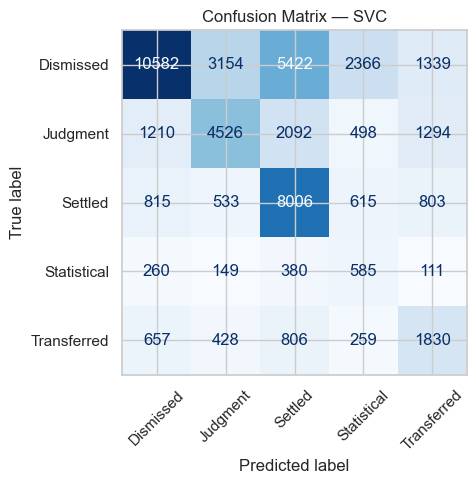

(0.5239942528735633,
 0.6067431771078464,
 0.5239942528735633,
 0.53696629968073,
 0.799467554750085)

In [39]:
t0 = time.time()
svc_clf = SVC(kernel="rbf", C=1.0, probability=True, class_weight="balanced", random_state=RANDOM_STATE)
svc_clf.fit(X_train_small, y_clf_train_small)
fit_seconds = time.time() - t0

pred_svc = svc_clf.predict(X_test_final)
proba_svc = svc_clf.predict_proba(X_test_final)

fitted_models_clf["SVC"] = svc_clf
test_preds_clf["SVC"] = pred_svc
test_probas_clf["SVC"] = proba_svc

evaluate_classifier("SVC", y_clf_test, pred_svc, proba_svc, fit_seconds, classes=svc_clf.classes_.tolist())

---
### Part A comparison table (5 algorithms)

In [40]:
comparison_clf_df = pd.DataFrame(results_clf).drop_duplicates(subset="Model", keep="last")
comparison_clf_df = comparison_clf_df.sort_values("F1", ascending=False).reset_index(drop=True)
comparison_clf_df.index = comparison_clf_df.index + 1
comparison_clf_df.insert(0, "Rank", comparison_clf_df.index)
comparison_clf_df[["Rank", "Model", "Accuracy", "Precision", "Recall", "F1", "ROC_AUC_OvR", "Fit_Seconds"]].round(4)

,Rank,Model,Accuracy,Precision,Recall,F1,ROC_AUC_OvR,Fit_Seconds
1,1,Decision Tree Classifier,0.5445,0.6201,0.5445,0.5624,0.8021,9.4175
2,2,KNN Classifier,0.5709,0.5597,0.5709,0.5578,0.7631,0.0086
3,3,SVC,0.5240,0.6067,0.5240,0.5370,0.7995,101.7182
4,4,Naive Bayes (Gaussian),0.5017,0.5067,0.5017,0.4997,0.7189,0.2372
5,5,Logistic Regression,0.4425,0.5654,0.4425,0.4637,0.7576,3.6219


---
## Classification Track — Part B (Algorithms 6–10)

#### 6. Random Forest Classifier


===== Random Forest Classifier =====
Accuracy=0.6333  Precision(weighted)=0.6710  Recall(weighted)=0.6333  F1(weighted)=0.6399  ROC-AUC(OvR, weighted)=0.8577  (fit time 80.7s)
              precision    recall  f1-score   support

   Dismissed       0.81      0.61      0.69     22863
    Judgment       0.66      0.62      0.64      9620
     Settled       0.53      0.77      0.63     10772
 Statistical       0.32      0.46      0.38      1485
 Transferred       0.43      0.50      0.46      3980

    accuracy                           0.63     48720
   macro avg       0.55      0.59      0.56     48720
weighted avg       0.67      0.63      0.64     48720



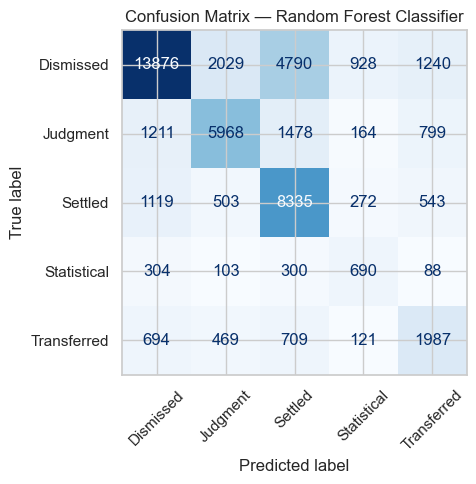

(0.6333333333333333,
 0.670957583204439,
 0.6333333333333333,
 0.6399004513053967,
 0.8576867568651698)

In [41]:
t0 = time.time()
rf_clf = RandomForestClassifier(n_estimators=200, max_depth=15, class_weight="balanced",
                                 random_state=RANDOM_STATE, n_jobs=-1)
rf_clf.fit(X_train_final, y_clf_train)
fit_seconds = time.time() - t0

pred_rf_clf = rf_clf.predict(X_test_final)
proba_rf_clf = rf_clf.predict_proba(X_test_final)

fitted_models_clf["Random Forest Classifier"] = rf_clf
test_preds_clf["Random Forest Classifier"] = pred_rf_clf
test_probas_clf["Random Forest Classifier"] = proba_rf_clf

evaluate_classifier("Random Forest Classifier", y_clf_test, pred_rf_clf, proba_rf_clf, fit_seconds,
                     classes=rf_clf.classes_.tolist())

Feature importance — Random Forest Classifier

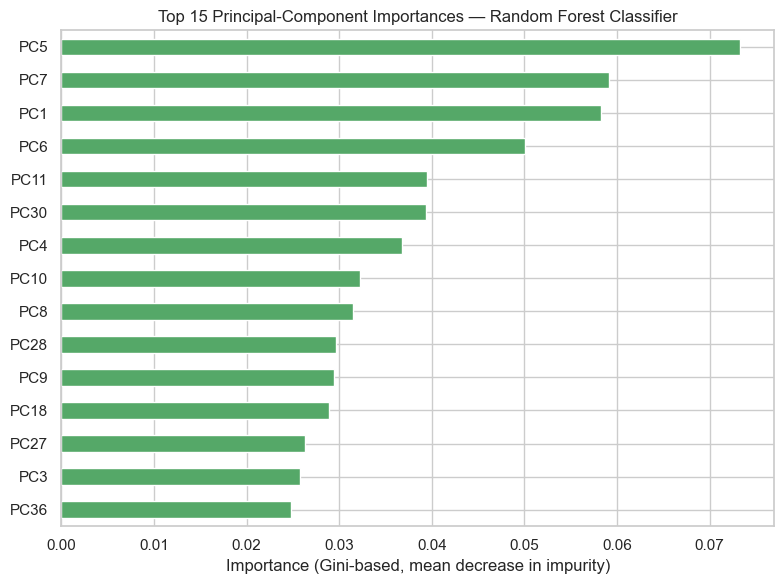

In [42]:
rf_importances = pd.Series(rf_clf.feature_importances_, index=X_train_final.columns)
top_rf = rf_importances.sort_values(ascending=False).head(15)

fig, ax = plt.subplots(figsize=(8, 6))
top_rf.sort_values().plot(kind="barh", ax=ax, color="#55A868")
ax.set_title("Top 15 Principal-Component Importances — Random Forest Classifier")
ax.set_xlabel("Importance (Gini-based, mean decrease in impurity)")
plt.tight_layout()
plt.show()

#### 7. AdaBoost Classifier


===== AdaBoost Classifier =====
Accuracy=0.5449  Precision(weighted)=0.5113  Recall(weighted)=0.5449  F1(weighted)=0.4980  ROC-AUC(OvR, weighted)=0.7462  (fit time 257.5s)
              precision    recall  f1-score   support

   Dismissed       0.57      0.81      0.67     22863
    Judgment       0.51      0.31      0.38      9620
     Settled       0.50      0.45      0.47     10772
 Statistical       0.00      0.00      0.00      1485
 Transferred       0.43      0.03      0.05      3980

    accuracy                           0.54     48720
   macro avg       0.40      0.32      0.32     48720
weighted avg       0.51      0.54      0.50     48720



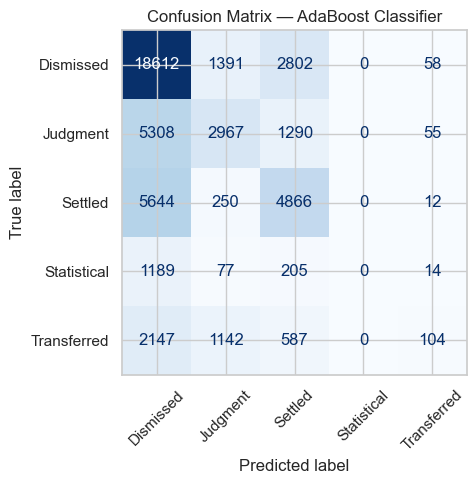

(0.5449302134646963,
 0.5113235191683168,
 0.5449302134646963,
 0.4979855777578692,
 0.7462023537271992)

In [43]:
t0 = time.time()
ada_clf = AdaBoostClassifier(n_estimators=100, learning_rate=0.5, random_state=RANDOM_STATE)
ada_clf.fit(X_train_final, y_clf_train)
fit_seconds = time.time() - t0

pred_ada = ada_clf.predict(X_test_final)
proba_ada = ada_clf.predict_proba(X_test_final)

fitted_models_clf["AdaBoost Classifier"] = ada_clf
test_preds_clf["AdaBoost Classifier"] = pred_ada
test_probas_clf["AdaBoost Classifier"] = proba_ada

evaluate_classifier("AdaBoost Classifier", y_clf_test, pred_ada, proba_ada, fit_seconds,
                     classes=ada_clf.classes_.tolist())

Staged test accuracy and feature importance — AdaBoost Classifier

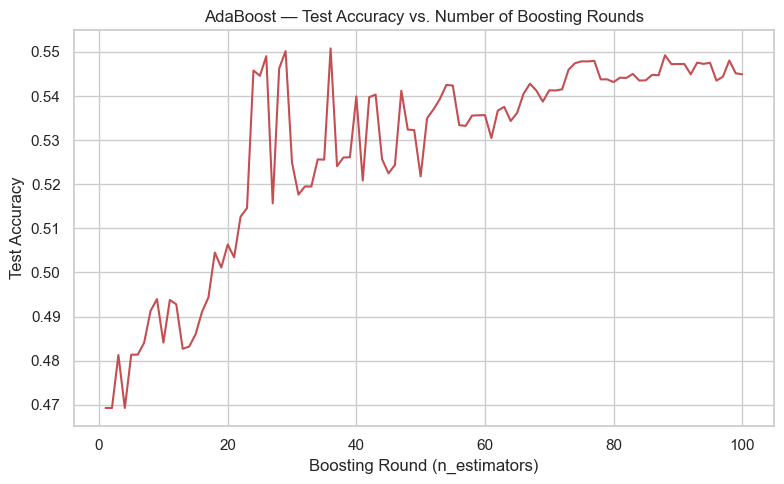

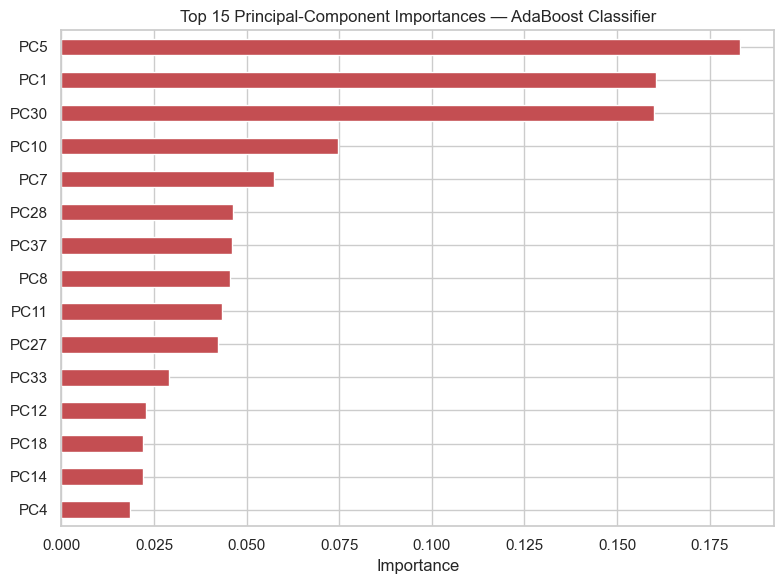

In [44]:
staged_acc = [accuracy_score(y_clf_test, pred) for pred in ada_clf.staged_predict(X_test_final)]

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(range(1, len(staged_acc) + 1), staged_acc, color="#C44E52")
ax.set_title("AdaBoost — Test Accuracy vs. Number of Boosting Rounds")
ax.set_xlabel("Boosting Round (n_estimators)")
ax.set_ylabel("Test Accuracy")
plt.tight_layout()
plt.show()

ada_importances = pd.Series(ada_clf.feature_importances_, index=X_train_final.columns)
top_ada = ada_importances.sort_values(ascending=False).head(15)
fig, ax = plt.subplots(figsize=(8, 6))
top_ada.sort_values().plot(kind="barh", ax=ax, color="#C44E52")
ax.set_title("Top 15 Principal-Component Importances — AdaBoost Classifier")
ax.set_xlabel("Importance")
plt.tight_layout()
plt.show()

#### 8. Gradient Boosting Classifier


===== Gradient Boosting Classifier =====
Accuracy=0.6255  Precision(weighted)=0.6365  Recall(weighted)=0.6255  F1(weighted)=0.6051  ROC-AUC(OvR, weighted)=0.8262  (fit time 2334.1s)
              precision    recall  f1-score   support

   Dismissed       0.65      0.80      0.72     22863
    Judgment       0.66      0.45      0.54      9620
     Settled       0.54      0.64      0.59     10772
 Statistical       0.87      0.15      0.25      1485
 Transferred       0.65      0.20      0.31      3980

    accuracy                           0.63     48720
   macro avg       0.68      0.45      0.48     48720
weighted avg       0.64      0.63      0.61     48720



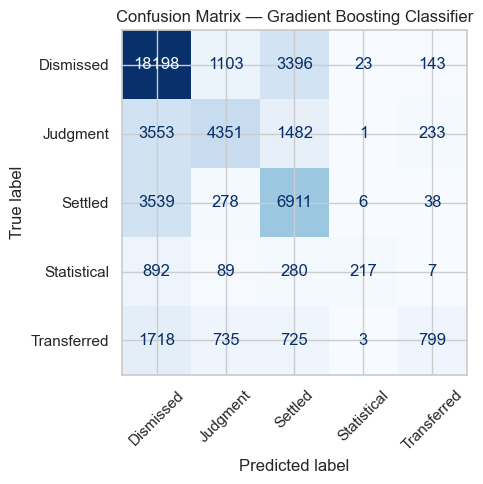

(0.6255336617405582,
 0.6365223968265589,
 0.6255336617405582,
 0.6050905861900253,
 0.8261980188162027)

In [49]:
t0 = time.time()
gb_clf = GradientBoostingClassifier(n_estimators=60, max_depth=3, learning_rate=0.1, random_state=RANDOM_STATE)
gb_clf.fit(X_train_final, y_clf_train)
fit_seconds = time.time() - t0

pred_gb_clf = gb_clf.predict(X_test_final)
proba_gb_clf = gb_clf.predict_proba(X_test_final)

fitted_models_clf["Gradient Boosting Classifier"] = gb_clf
test_preds_clf["Gradient Boosting Classifier"] = pred_gb_clf
test_probas_clf["Gradient Boosting Classifier"] = proba_gb_clf

evaluate_classifier("Gradient Boosting Classifier", y_clf_test, pred_gb_clf, proba_gb_clf, fit_seconds,
                     classes=gb_clf.classes_.tolist())

Training deviance curve and feature importance — Gradient Boosting Classifier

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(range(1, gb_clf.n_estimators_ + 1), gb_clf.train_score_, color="#4C72B0")
ax.set_title("Gradient Boosting — Training Deviance vs. Boosting Stage")
ax.set_xlabel("Boosting Stage")
ax.set_ylabel("Training Deviance (loss)")
plt.tight_layout()
plt.show()

gb_importances = pd.Series(gb_clf.feature_importances_, index=X_train_final.columns)
top_gb = gb_importances.sort_values(ascending=False).head(15)
fig, ax = plt.subplots(figsize=(8, 6))
top_gb.sort_values().plot(kind="barh", ax=ax, color="#4C72B0")
ax.set_title("Top 15 Principal-Component Importances — Gradient Boosting Classifier")
ax.set_xlabel("Importance")
plt.tight_layout()
plt.show()

#### 9. Bagging Classifier


===== Bagging Classifier =====
Accuracy=0.6325  Precision(weighted)=0.6714  Recall(weighted)=0.6325  F1(weighted)=0.6404  ROC-AUC(OvR, weighted)=0.8546  (fit time 111.9s)
              precision    recall  f1-score   support

   Dismissed       0.80      0.60      0.69     22863
    Judgment       0.67      0.65      0.66      9620
     Settled       0.55      0.75      0.64     10772
 Statistical       0.29      0.47      0.36      1485
 Transferred       0.40      0.51      0.45      3980

    accuracy                           0.63     48720
   macro avg       0.54      0.60      0.56     48720
weighted avg       0.67      0.63      0.64     48720



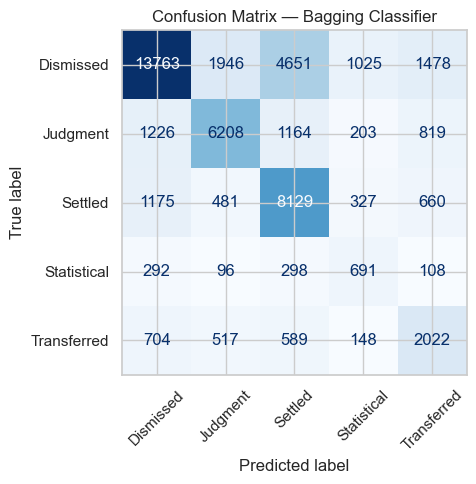

(0.6324507389162561,
 0.6713790712406441,
 0.6324507389162561,
 0.6403734032098864,
 0.854585737513494)

In [50]:
t0 = time.time()
bag_clf = BaggingClassifier(
    estimator=DecisionTreeClassifier(max_depth=15, class_weight="balanced", random_state=RANDOM_STATE),
    n_estimators=50, max_samples=0.8, random_state=RANDOM_STATE, n_jobs=-1,
)
bag_clf.fit(X_train_final, y_clf_train)
fit_seconds = time.time() - t0

pred_bag = bag_clf.predict(X_test_final)
proba_bag = bag_clf.predict_proba(X_test_final)

fitted_models_clf["Bagging Classifier"] = bag_clf
test_preds_clf["Bagging Classifier"] = pred_bag
test_probas_clf["Bagging Classifier"] = proba_bag

evaluate_classifier("Bagging Classifier", y_clf_test, pred_bag, proba_bag, fit_seconds,
                     classes=bag_clf.classes_.tolist())

Feature importance (averaged across base estimators) — Bagging Classifier

In [ ]:
bag_importances_matrix = np.array([est.feature_importances_ for est in bag_clf.estimators_])
bag_importances = pd.Series(bag_importances_matrix.mean(axis=0), index=X_train_final.columns)
top_bag = bag_importances.sort_values(ascending=False).head(15)

fig, ax = plt.subplots(figsize=(8, 6))
top_bag.sort_values().plot(kind="barh", ax=ax, color="#8172B2")
ax.set_title("Top 15 Principal-Component Importances — Bagging Classifier (averaged across 50 trees)")
ax.set_xlabel("Mean Importance Across Base Estimators")
plt.tight_layout()
plt.show()

#### 10. MLP Classifier (Neural Network)

In [ ]:
t0 = time.time()
mlp_clf = MLPClassifier(hidden_layer_sizes=(64, 32), activation="relu", max_iter=300,
                         early_stopping=True, random_state=RANDOM_STATE)
mlp_clf.fit(X_train_final, y_clf_train)
fit_seconds = time.time() - t0

pred_mlp = mlp_clf.predict(X_test_final)
proba_mlp = mlp_clf.predict_proba(X_test_final)

fitted_models_clf["MLP Classifier"] = mlp_clf
test_preds_clf["MLP Classifier"] = pred_mlp
test_probas_clf["MLP Classifier"] = proba_mlp

evaluate_classifier("MLP Classifier", y_clf_test, pred_mlp, proba_mlp, fit_seconds,
                     classes=mlp_clf.classes_.tolist())
print(f"Converged after {mlp_clf.n_iter_} iterations.")

Training loss curve — MLP Classifier

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(mlp_clf.loss_curve_, color="#DA8BC3")
ax.set_title("MLP Classifier — Training Loss Curve")
ax.set_xlabel("Training Iteration")
ax.set_ylabel("Loss")
plt.tight_layout()
plt.show()

---
### Consolidated 10-algorithm comparison table (Part A + Part B)

In [ ]:
comparison_clf_df_full = pd.DataFrame(results_clf).drop_duplicates(subset="Model", keep="last")
comparison_clf_df_full = comparison_clf_df_full.sort_values("F1", ascending=False).reset_index(drop=True)
comparison_clf_df_full.index = comparison_clf_df_full.index + 1
comparison_clf_df_full.insert(0, "Rank", comparison_clf_df_full.index)

print(f"Total algorithms compared: {len(comparison_clf_df_full)}")
comparison_clf_df_full[["Rank", "Model", "Accuracy", "Precision", "Recall", "F1", "ROC_AUC_OvR", "Fit_Seconds"]].round(4)

In [ ]:
fig, ax = plt.subplots(figsize=(9, 6))
plot_df = comparison_clf_df_full.sort_values("F1")
part_a_models = ["Logistic Regression", "KNN Classifier", "Naive Bayes (Gaussian)",
                  "Decision Tree Classifier", "SVC"]
colors = ["#C44E52" if m in part_a_models else "#4C72B0" for m in plot_df["Model"]]
ax.barh(plot_df["Model"], plot_df["F1"], color=colors)
ax.set_xlabel("Weighted F1 Score")
ax.set_title("All 10 Classification Algorithms — Weighted F1 (red = Part A, blue = Part B)")
plt.tight_layout()
plt.show()

---
### Final model selection & hyperparameter tuning

In [ ]:
best_model_name = comparison_clf_df_full.iloc[0]["Model"]
f1_before = comparison_clf_df_full.loc[comparison_clf_df_full["Model"] == best_model_name, "F1"].values[0]
print(f"Best model by weighted F1: {best_model_name}")
print(f"F1 before tuning: {f1_before:.4f}")

In [ ]:
tuning_grids = {
    "Random Forest Classifier": (
        RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1),
        {"n_estimators": [150, 250, 350], "max_depth": [10, 15, 20, None],
         "min_samples_leaf": [1, 2, 5], "max_features": ["sqrt", 0.5, None]},
    ),
    "Gradient Boosting Classifier": (
        GradientBoostingClassifier(random_state=RANDOM_STATE),
        {"n_estimators": [100, 150, 200], "max_depth": [2, 3, 4], "learning_rate": [0.05, 0.1, 0.2]},
    ),
    "Bagging Classifier": (
        BaggingClassifier(estimator=DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE),
                           random_state=RANDOM_STATE, n_jobs=-1),
        {"n_estimators": [30, 50, 80], "max_samples": [0.6, 0.8, 1.0], "estimator__max_depth": [10, 15, None]},
    ),
    "AdaBoost Classifier": (
        AdaBoostClassifier(random_state=RANDOM_STATE),
        {"n_estimators": [50, 100, 150], "learning_rate": [0.1, 0.5, 1.0]},
    ),
}

TUNE_SAMPLE_SIZE = 60000
rng = np.random.RandomState(RANDOM_STATE)
if len(X_train_final) > TUNE_SAMPLE_SIZE:
    from sklearn.model_selection import train_test_split as tts
    X_train_tune, _, y_train_tune, _ = tts(X_train_final, y_clf_train, train_size=TUNE_SAMPLE_SIZE,
                                            stratify=y_clf_train, random_state=RANDOM_STATE)
else:
    X_train_tune, y_train_tune = X_train_final, y_clf_train

if best_model_name in tuning_grids:
    estimator, param_dist = tuning_grids[best_model_name]
    t0 = time.time()
    search = RandomizedSearchCV(estimator, param_distributions=param_dist, n_iter=8, cv=3,
                                 scoring="f1_weighted", random_state=RANDOM_STATE, n_jobs=-1)
    search.fit(X_train_tune, y_train_tune)
    print(f"Best params: {search.best_params_}  |  Best CV F1: {round(search.best_score_, 4)}")

    best_params = search.best_params_
    tuned_model = type(estimator)(**{**estimator.get_params(), **best_params})
    tuned_model.fit(X_train_final, y_clf_train)

    pred_tuned = tuned_model.predict(X_test_final)
    proba_tuned = tuned_model.predict_proba(X_test_final)
    f1_after = f1_score(y_clf_test, pred_tuned, average="weighted", zero_division=0)

    print(f"F1 before tuning: {f1_before:.4f}")
    print(f"F1 after tuning:  {f1_after:.4f}")
    print(f"Improvement: {f1_after - f1_before:+.4f}")

    fitted_models_clf[f"{best_model_name} (Tuned)"] = tuned_model
    test_preds_clf[f"{best_model_name} (Tuned)"] = pred_tuned
    test_probas_clf[f"{best_model_name} (Tuned)"] = proba_tuned
else:
    print(f"'{best_model_name}' has no pre-built grid above. Add one following the same pattern.")

---
### Save final results

In [ ]:
import os
os.makedirs("../data/processed", exist_ok=True)
os.makedirs("../models", exist_ok=True)

joblib.dump({
    "comparison_clf_df_full": comparison_clf_df_full,
    "best_model_name": best_model_name,
    "fitted_models_clf": fitted_models_clf,
    "CLASS_LABELS": CLASS_LABELS,
}, "../data/processed/classification_final_results.pkl")

final_clf_key = f"{best_model_name} (Tuned)" if f"{best_model_name} (Tuned)" in fitted_models_clf else best_model_name
joblib.dump(fitted_models_clf[final_clf_key], "../models/best_classifier.pkl")

print(f"Saved results. Best classifier: '{final_clf_key}'")